# Active Subspace Analysis for the N+2 Supersonic Passenger Jet

__Trent Lukaczyk__, Stanford University

__Paul Constantine__, Colorado School of Mines (2016 notebook)

<br>

In this notebook, we apply _active subspaces_ to the lift, drag and equivalent area of the Lockheed Martin N+2 supersonic passenger jet, the example of §4.3.3 of Trent Lukaczyk's dissertation [[1]][R1], using his SU2 runs. The notebook uses the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy and matplotlib (see the repository's `requirements.txt`) and takes under a minute.

### The N+2 supersonic passenger jet

The N+2 is a design for a supersonic passenger jet that carries 70 passengers, developed in design studies by NASA, Lockheed Martin, General Electric and Stanford University ([[1]][R1] §2.5.3). The flight condition is a freestream Mach number of 1.7 at an angle of attack of 2.1°, with a baseline cruise lift coefficient of 0.14. The data come from the configuration that [[1]][R1] §2.5.3.2 calls the boom mesh with active engines: a half-body geometry with a near-field region for the pressure signature, parameterized by **105** free-form deformation (FFD) design variables. Each variable is the z-displacement of an FFD control point. [[1]][R1] Fig. 2.20 places the control points on four components: the main wing (50), the tail (24), the aft deck (16) and the fuselage (15). The location and shape of the engines are frozen. Each run took 120 minutes on 96 cores ([[1]][R1] p. 107).

**Inputs (105)**

Variable | Lower bound | Upper bound | Density
--- | --- | --- | ---
x01–x105 | −0.3 | 0.3 | Uniform

- Which columns belong to the wing, tail, aft deck and fuselage is not recorded (the author, 2026-10-30). The eigenvector plots below are therefore labelled by column index only, not by component.
- The units of the displacements are not recorded. The sampled values fill $[-0.3, 0.3]$ (printed below), the bounds the 2016 notebook gives. [[1]][R1] Eq. (2.21) states the optimization bounds as $-3.0 \le x_i \le 3.0$. Why the two differ (a typo, or different bounds for the optimization) is unexplained.

**Outputs (3)**, each with its gradient from SU2's continuous adjoint

Variable | Description
--- | ---
Lift | lift coefficient $C_L$
Drag | drag coefficient $C_D$
Equiv Area | equivalent-area functional $\Delta A_e$ ([[1]][R1] Eq. (2.2), p. 17): the mean squared difference between the aircraft's near-field equivalent-area distribution and a target distribution, over a sampling cylinder around the aircraft. It is zero when the distributions match. Changes in the equivalent area correlate with changes in the loudness of the sonic boom on the ground, so $\Delta A_e$ is a near-field proxy for boom loudness.

- **Samples.** The file has 310 runs. [[1]][R1] p. 107 reports "315 sampled designs, 305 of which were retained after filtering for results that converged more than $1\times 10^{-6}$". Why the file has 310 rows, and whether it includes runs that failed that filter, is unexplained (the author, 2026-10-30). Run 1 is the baseline design (all $x_i = 0$). We use all 310 rows.
- **Scale of $\Delta A_e$.** The stored values run from 5.5 to 1666. In [[1]][R1] Eq. (2.21) the same quantity is constrained by $\Delta A_e \le 10^{-4}$, so the stored values are on another scale, which is not recorded.
- **Gradients.** SU2's continuous adjoint ([[1]][R1] §3.3.2.1). [[1]][R1] checked the accuracy of these gradients only on NACA0012 (Table 3.4, p. 72), not on the N+2. We check them against the data in the section "Gradient quality" below.

The data are stored SU2 output: the runs cannot be repeated from this repository. See `DATA.md`.

### Active subspaces

Consider a scalar output $f$ as a function of $m$ normalized inputs $\mathbf x\in[-1,1]^m$ with a probability density $\rho$. The active subspace method is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\nabla f(\mathbf x)^T\rho(\mathbf x)\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

with the eigenvalues in descending order. The eigenpairs satisfy $\lambda_i = \int(\nabla f^T\mathbf w_i)^2\rho\ d\mathbf x$, so the eigenvalues measure how much $f$ changes along the corresponding eigenvectors. If the first $n<m$ eigenvalues are much larger than the rest, $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x)$, where $\mathbf W_1$ holds the first $n$ eigenvectors and $\mathbf y = \mathbf W_1^T\mathbf x$ are the _active variables_. We estimate $\mathbf C$ by Monte Carlo from the $M$ gradient samples, $\mathbf C \approx \frac 1 M\sum_{j=1}^M\nabla f_j\nabla f_j^T$, and each output has its own active subspace.

### References

[[1]][R1] T.W. Lukaczyk. _Surrogate Modeling and Active Subspaces for Efficient Optimization of Supersonic Aircraft_. PhD dissertation, Stanford University, June 2015. http://purl.stanford.edu/xx611nd3190 (§2.5.3, pp. 38–42; §4.3.3, pp. 107–112). The dissertation is licensed CC BY-NC 3.0 US; that license covers its text, not this data set.

[[2]][R2] T.W. Lukaczyk, F. Palacios, J.J. Alonso, and P.G. Constantine. _Active Subspaces for Shape Optimization_. 10th AIAA Multidisciplinary Design Optimization Conference, AIAA SciTech, National Harbor, MD, January 2014. AIAA 2014-1171. doi:10.2514/6.2014-1171. The method applied to the ONERA M6 wing; see this repository's [ONERA_M6_Wing](../ONERA_M6_Wing/ONERA_M6_Wing.ipynb) notebook.

[[3]][R3] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM Journal on Scientific Computing, 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[R1]: http://purl.stanford.edu/xx611nd3190
[R2]: https://doi.org/10.2514/6.2014-1171
[R3]: https://doi.org/10.1137/130916138

### Acknowledgments

The SU2 runs were funded by the NASA N+2 Supersonics Program and the Lockheed Martin Corporation ([[1]][R1] p. vii).

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

t_start = time.perf_counter()
rng = np.random.default_rng(2015)        # the only source of randomness (the bootstraps) in this notebook

Import the data set. Distinguish inputs, outputs, and gradients. The file `LM104X.txt` (named after the 2016 notebook's "LM104X") has a header line and one row per SU2 run: the run number, the 105 inputs `x01`–`x105`, the three outputs, and their gradients `d-lift01`–`d-lift105`, `d-drag01`–`d-drag105` and `d-ea01`–`d-ea105`. The inputs are in physical units ($[-0.3, 0.3]$), and the gradients are derivatives with respect to them.

In [2]:
with open('LM104X.txt') as fh:
    header = fh.readline().strip().split(',')
data = np.loadtxt('LM104X.txt', delimiter=',', skiprows=1)

m = 105                                  # number of input parameters
run = data[:, 0].astype(int)
X = data[:, 1:m+1]                       # inputs, physical units
qois = ['Lift', 'Drag', 'Equiv Area']
f = {q: data[:, m+1+j] for j, q in enumerate(qois)}
G = {q: data[:, m+4+j*m:m+4+(j+1)*m] for j, q in enumerate(qois)}   # gradients w.r.t. the PHYSICAL inputs
names = header[1:m+1]
M = len(X)

print(f'{M} runs (numbers {run[0]}-{run[-1]}), {m} inputs; columns {header[m+1:m+4]}, '
      f'gradients {header[m+4]}..{header[-1]}')
print(f'inputs in [{X.min():.5f}, {X.max():.5f}], std {X.std():.4f} (uniform on [-0.3, 0.3]: {0.3/np.sqrt(3):.4f}); '
      f'distinct input rows: {len(np.unique(X, axis=0))}')
print(f'run 1 is the baseline (all inputs 0): {np.all(X[0] == 0)}')
for q in qois:
    print(f'{q:>10}: min {f[q].min():.4g}, max {f[q].max():.4g}, baseline {f[q][0]:.4g}')

310 runs (numbers 1-310), 105 inputs; columns ['Lift', 'Drag', 'Equiv Area'], gradients d-lift01..d-ea105
inputs in [-0.29998, 0.29999], std 0.1729 (uniform on [-0.3, 0.3]: 0.1732); distinct input rows: 310
run 1 is the baseline (all inputs 0): True
      Lift: min 0.1228, max 0.1525, baseline 0.1387
      Drag: min 0.01717, max 0.01982, baseline 0.01798
Equiv Area: min 5.546, max 1666, baseline 54.89


Compute the active subspaces. The input space is the box $[-0.3, 0.3]^{105}$ with the uniform density; `ac.active_subspace` takes the physical gradients and maps them to the normalized coordinates $[-1, 1]^{105}$ by the chain rule, multiplying each by the half-width 0.3.

The 2016 version of this notebook normalized the inputs but passed the physical gradients as they were. Its eigenvectors are the same as ours (all 105 inputs have the same range), but its eigenvalues are $1/0.3^2 \approx 11.1$ times ours. We first check this with the 2016 computation (the eigendecomposition of $\frac 1 M\sum_j\nabla f_j\nabla f_j^T$ for the raw gradients), then compute the subspaces with 200 bootstrap replicates, as in 2016.

Eigenvector signs are arbitrary. v1 makes each eigenvector's largest component positive; we use `ac.orient` to make the first component of the first three eigenvectors positive instead, the 2016 package's rule. With that rule the signs of $\mathbf w_1$ also match the sufficient summary plots of [[1]][R1] Fig. 4.15: lift and drag decrease along the active variable, and the equivalent area grows toward its positive end. (v1's own rule would mirror the drag $\mathbf w_1$.)

We keep the bootstrap replicates of the first three eigenvectors, which the 2016 notebook plotted. v1 warns (below) that for lift and drag the replicates of the third eigenvector are poorly aligned with it: for both outputs $\lambda_3$ and $\lambda_4$ are close, so $\mathbf w_3$ is ill-defined. Its band in the eigenvector plot shows the spread.

In [3]:
space = ac.Uniform(np.full(m, -0.3), np.full(m, 0.3), names=names)
e1 = np.eye(m)[:, [0, 0, 0]]             # reference for the 2016 sign rule: first component positive
fmt = lambda v: ', '.join(f'{x:.4g}' for x in v)

print('check against the 2016 computation')
for q in qois:
    lam16, W16 = np.linalg.eigh(G[q].T @ G[q] / M)
    lam16, W16 = lam16[::-1], W16[:, ::-1]
    s = ac.active_subspace(space=space, grads=G[q], qoi=q)
    print(f'  {q:>10}: lambda_1..3 = {fmt(s.eigenvalues[:3])}; 2016 values x 0.09 = {fmt(lam16[:3] * 0.09)}; '
          f'max relative difference {np.max(np.abs(s.eigenvalues[:3] / (lam16[:3] * 0.09) - 1)):.0e}; '
          f'|1 - |w1 . w1(2016)|| = {abs(1 - abs(s.W[:, 0] @ W16[:, 0])):.0e}')

sub = {}
for q in qois:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        s = ac.active_subspace(space=space, grads=G[q], nboot=200, bootstrap_vectors=3, rng=rng, qoi=q)
    v1_flips = np.sign(s.W[0, 0])
    sub[q] = ac.orient(s, by='reference', reference=e1, columns=3)
    print(f'\n{q}: lambda_1..6 = {fmt(sub[q].eigenvalues[:6])}')
    for w in caught:
        print(f'{"":>{len(q)}}  {type(w.message).__name__}: {w.message}')
    print(f'{"":>{len(q)}}  lambda_k/lambda_1, k = 2..5: {fmt(sub[q].eigenvalues[1:5] / sub[q].eigenvalues[0])}')
    print(f'{"":>{len(q)}}  dimension chosen by the eigenvalue-gap rule (EVG): n = {sub[q].n}; '
          f'orient flipped w1 relative to the v1 default: {v1_flips < 0}')

check against the 2016 computation
        Lift: lambda_1..3 = 4.188e-05, 2.15e-08, 8.093e-09; 2016 values x 0.09 = 4.188e-05, 2.15e-08, 8.093e-09; max relative difference 2e-14; |1 - |w1 . w1(2016)|| = 0e+00
        Drag: lambda_1..3 = 1.476e-07, 3.509e-08, 1.16e-08; 2016 values x 0.09 = 1.476e-07, 3.509e-08, 1.16e-08; max relative difference 2e-15; |1 - |w1 . w1(2016)|| = 9e-16
  Equiv Area: lambda_1..3 = 978.6, 3.106, 1.47; 2016 values x 0.09 = 978.6, 3.106, 1.47; max relative difference 3e-15; |1 - |w1 . w1(2016)|| = 2e-16



Lift: lambda_1..6 = 4.188e-05, 2.15e-08, 8.093e-09, 5.825e-09, 4.125e-09, 1.88e-09
      lambda_k/lambda_1, k = 2..5: 0.0005133, 0.0001932, 0.0001391, 9.85e-05
      dimension chosen by the eigenvalue-gap rule (EVG): n = 1; orient flipped w1 relative to the v1 default: False



Drag: lambda_1..6 = 1.476e-07, 3.509e-08, 1.16e-08, 9.778e-09, 2.403e-09, 1.482e-09
      lambda_k/lambda_1, k = 2..5: 0.2378, 0.0786, 0.06625, 0.01628
      dimension chosen by the eigenvalue-gap rule (EVG): n = 1; orient flipped w1 relative to the v1 default: True



Equiv Area: lambda_1..6 = 978.6, 3.106, 1.47, 0.7597, 0.384, 0.3321
            lambda_k/lambda_1, k = 2..5: 0.003174, 0.001503, 0.0007763, 0.0003924
            dimension chosen by the eigenvalue-gap rule (EVG): n = 1; orient flipped w1 relative to the v1 default: False


Plot the eigenvalues and subspace errors, with the minimum-to-maximum ranges over the bootstrap replicates (the 2016 band; the v1 default is a 95% percentile band). The dotted line marks the dimension that the eigenvalue-gap rule chose.

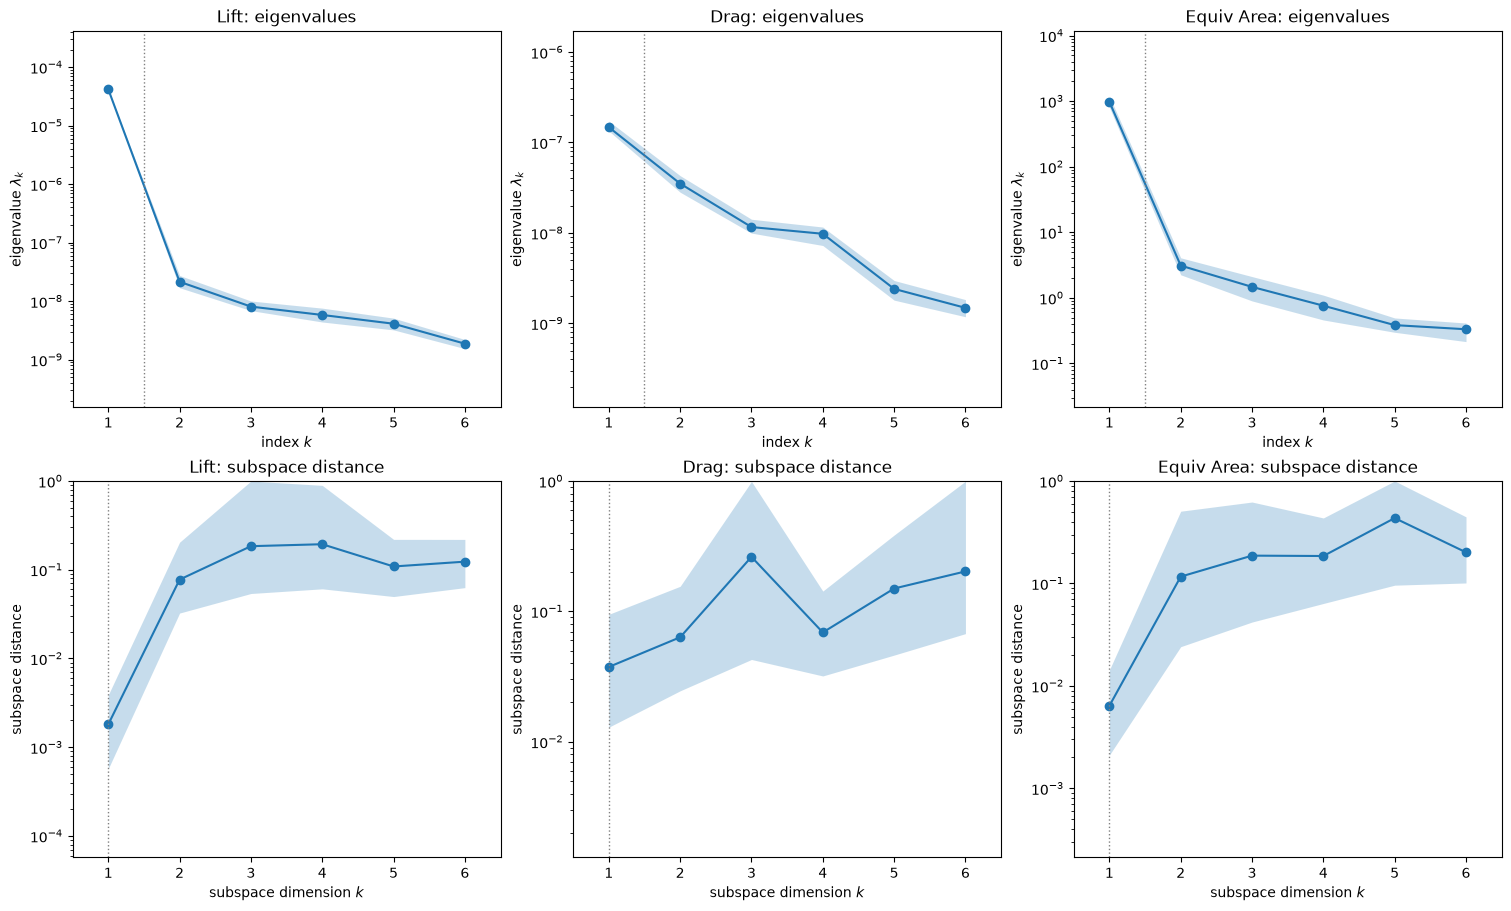

In [4]:
k = 6   # number of eigenvalues to plot, as in 2016
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout='constrained')
for j, q in enumerate(qois):
    ac.plotting.plot_eigenvalues(sub[q], interval='minmax', k_max=k, ax=axes[0, j])
    ac.plotting.plot_subspace_errors(sub[q], interval='minmax', k_max=k, ax=axes[1, j])
    axes[0, j].set_title(f'{q}: eigenvalues')
    axes[1, j].set_title(f'{q}: subspace distance')

Lift and the equivalent area have a large gap after the first eigenvalue: $\lambda_2/\lambda_1$ is about $5\times 10^{-4}$ and $3\times 10^{-3}$ (printed above). The drag eigenvalues decay more slowly ($\lambda_2/\lambda_1 \approx 0.24$, $\lambda_3/\lambda_1 \approx 0.08$). This is the reading of [[1]][R1] p. 107: for drag "the first mode can be considered very important, followed closely by the second and third modes".

The eigenvalue-gap rule picks $n = 1$ for all three outputs. We keep $n = 1$ for lift and the equivalent area, and take $n = 2$ for drag, where the second eigenvalue is a quarter of the first. To check these choices, we fit a polynomial in the first $n$ active variables, linear for lift (which [[1]][R1] p. 107 calls a linear trend) and quadratic for drag and the equivalent area, and print its in-sample and leave-one-out $R^2$ for $n = 1, \dots, 4$.

In [5]:
n_use = {'Lift': 1, 'Drag': 2, 'Equiv Area': 1}
degree = {'Lift': 1, 'Drag': 2, 'Equiv Area': 2}
r2 = {}
print(f'{"":>10}  degree   ' + '      '.join(f'n = {n}' for n in range(1, 5)) + '   (in-sample R^2 / leave-one-out R^2)')
for q in qois:
    row = []
    for n in range(1, 5):
        sur = ac.fit_surrogate(X=X, f=f[q], subspace=ac.with_dimension(sub[q], n), kind='poly', degree=degree[q])
        r2[q, n] = 1 - np.sum(np.asarray(sur.residuals)**2) / np.sum((f[q] - f[q].mean())**2)
        row.append(f'{r2[q, n]:.3f}/{sur.loo_r_squared:.3f}')
    print(f'{q:>10}  {degree[q]:>6}   ' + '  '.join(row))
sub = {q: ac.with_dimension(sub[q], n_use[q]) for q in qois}
print('\nchosen: ' + '; '.join(f'{q} n = {n_use[q]} (in-sample R^2 {r2[q, n_use[q]]:.3f})' for q in qois))

            degree   n = 1      n = 2      n = 3      n = 4   (in-sample R^2 / leave-one-out R^2)
      Lift       1   0.819/0.817  0.846/0.843  0.874/0.870  0.901/0.898
      Drag       2   0.507/0.494  0.760/0.748  0.776/0.758  0.779/0.751
Equiv Area       2   0.823/0.818  0.825/0.814  0.832/0.813  0.884/0.864

chosen: Lift n = 1 (in-sample R^2 0.819); Drag n = 2 (in-sample R^2 0.760); Equiv Area n = 1 (in-sample R^2 0.823)


For drag, the second active variable raises $R^2$ from 0.51 to 0.76, and the third and fourth add little. For the equivalent area, the second and third add little. Lift's $R^2$ of 0.82 in one variable is lower than its large eigenvalue gap suggests, and it keeps rising with $n$ (0.90 at $n = 4$). The section "Gradient quality" shows why: lift is linear in the inputs, but its adjoint $\mathbf w_1$ is about 25° from the true gradient direction, and each further eigenvector recovers part of the difference.

Next we plot the 1- and 2-dimensional sufficient summary plots, which show each output against the first one or two active variables ($\mathbf w_1^T\mathbf x$ and $\mathbf w_2^T\mathbf x$, with $\mathbf x$ the normalized inputs).

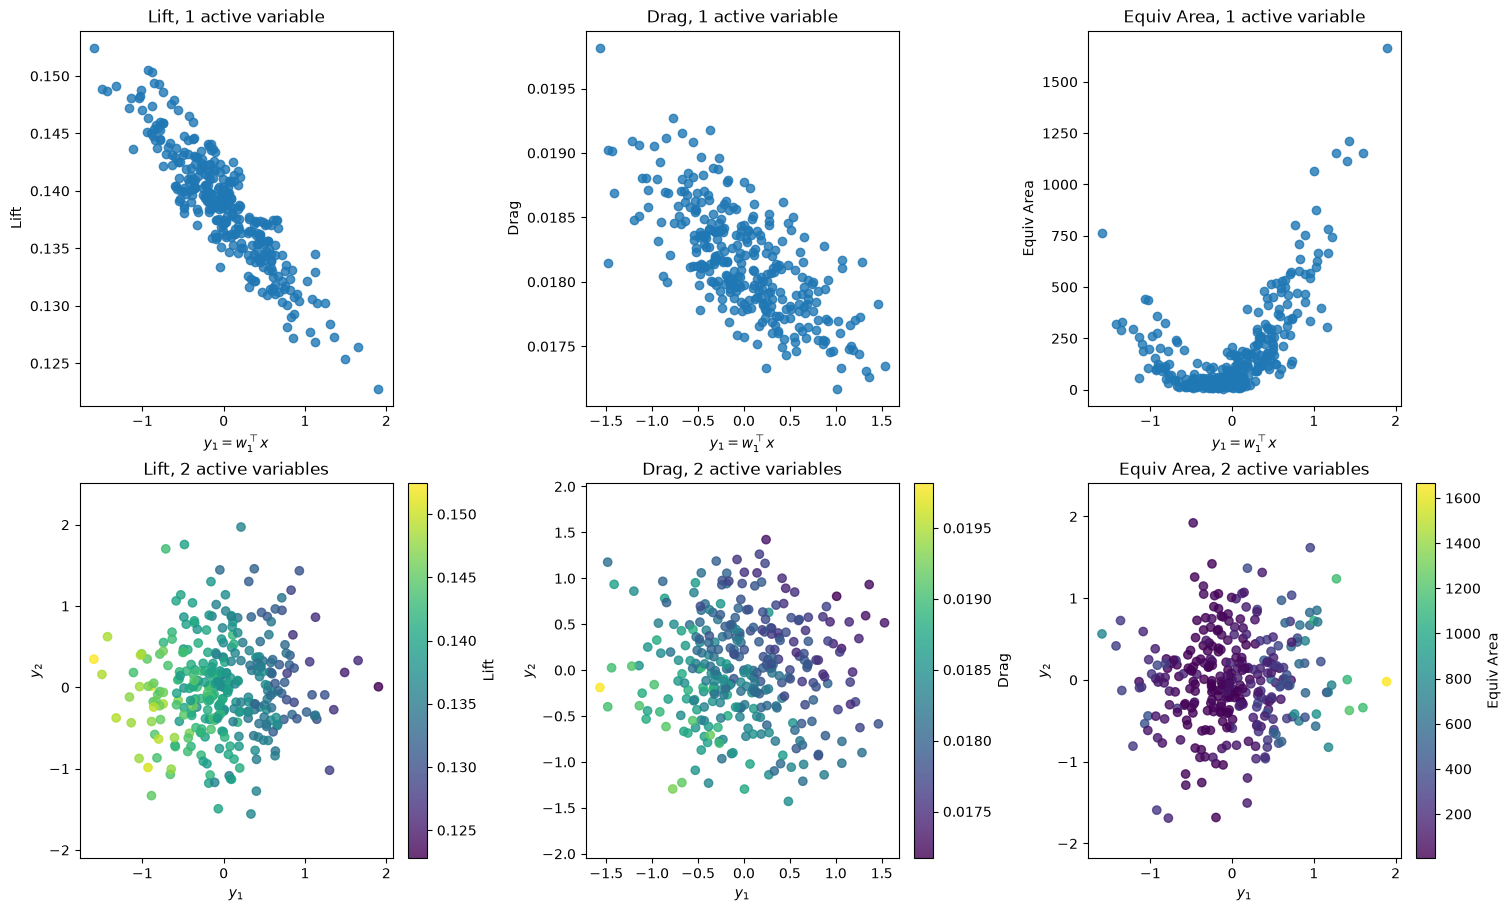

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout='constrained')
for j, q in enumerate(qois):
    s2 = ac.with_dimension(sub[q], 2)
    for i, dims in enumerate((1, 2)):
        ac.plotting.plot_sufficient_summary(s2, X=X, f=f[q], dims=dims, ax=axes[i, j])
        axes[i, j].set_title(f'{q}, {dims} active variable{"s" if dims == 2 else ""}')

Lift and the equivalent area collapse onto one active variable: lift along a line and the equivalent area along a parabola, as [[1]][R1] p. 107 describes. The 1-dimensional drag plot does not collapse; the 2-dimensional one shows the drag varying along both active variables.

The eigenvector components measure the sensitivity of each output to each input. We plot the first three eigenvectors for each output, with the minimum-to-maximum range of the bootstrap replicates. The components are labelled by column (`x01`–`x105`) only, since the mapping of columns to the wing, tail, aft deck and fuselage is not recorded.

      Lift: largest |w1| components: x26 (+0.29), x27 (+0.27), x41 (-0.25), x28 (+0.21), x42 (-0.21)
      Drag: largest |w1| components: x69 (-0.34), x70 (-0.26), x26 (+0.25), x66 (-0.23), x67 (-0.22)
Equiv Area: largest |w1| components: x26 (+0.32), x27 (+0.28), x41 (-0.27), x28 (+0.22), x42 (-0.22)
|w1(Lift) . w1(Equiv Area)| = 0.984, |w1(Lift) . w1(Drag)| = 0.752


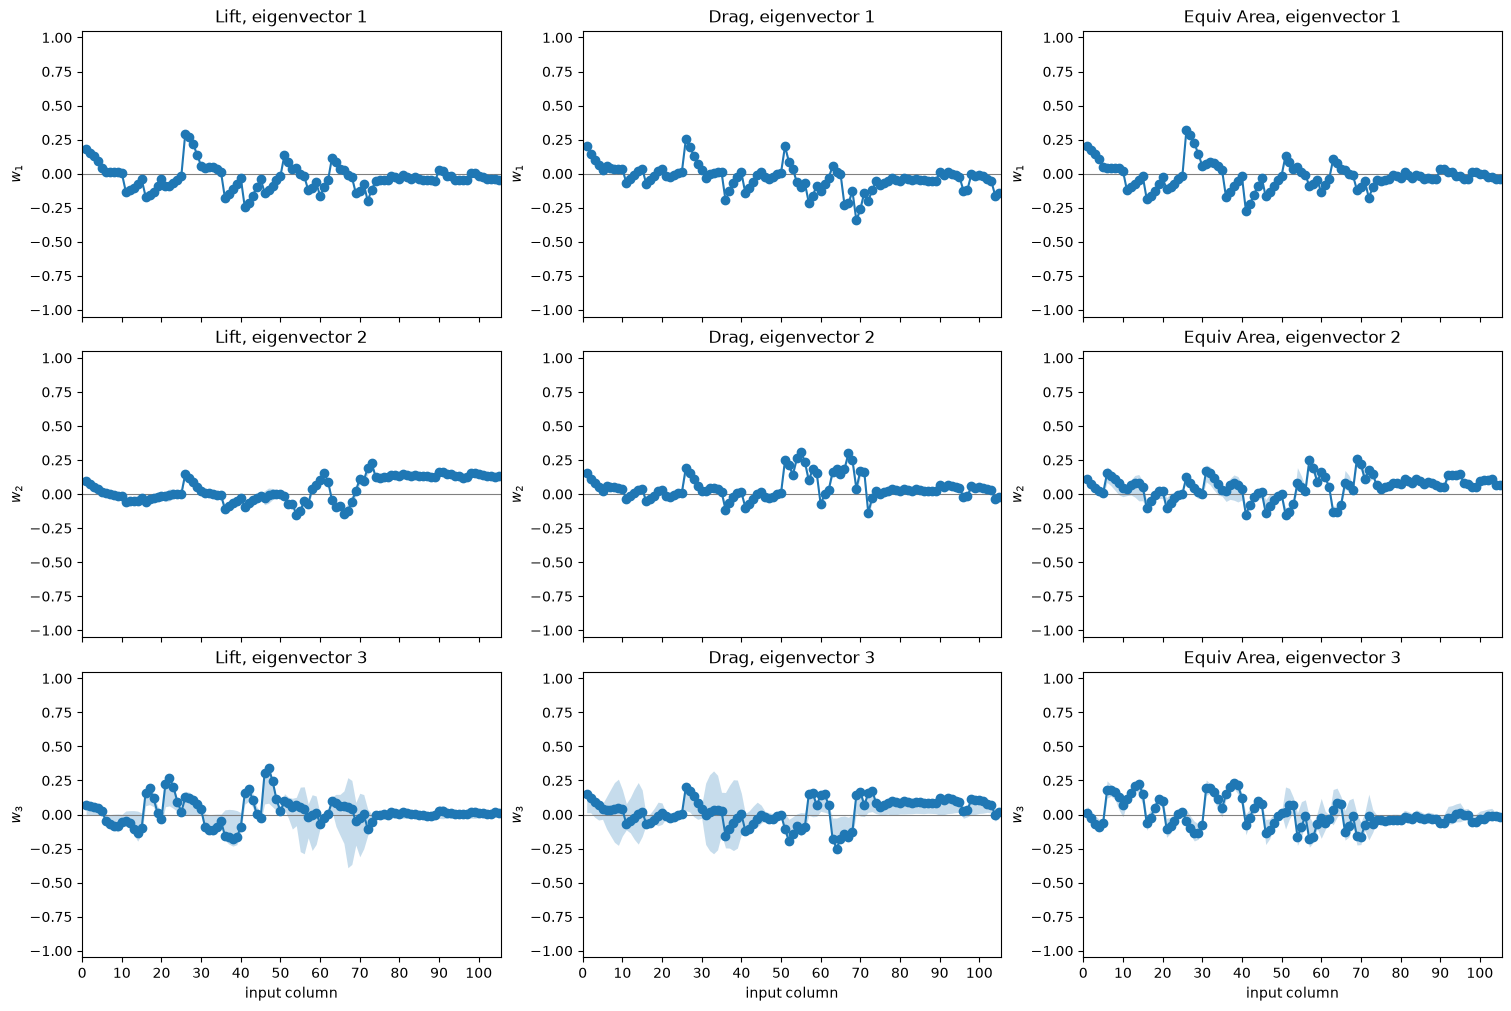

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True, layout='constrained')
for j, q in enumerate(qois):
    ac.plotting.plot_eigenvectors(sub[q], indices=[0, 1, 2], interval='minmax', ax=axes[:, j])
    for i in range(3):
        axes[i, j].set_title(f'{q}, eigenvector {i + 1}')
        axes[i, j].set_xticks(np.arange(0, m + 1, 10))
for ax in axes[-1]:
    ax.set_xlabel('input column')
for q in qois:
    w1 = sub[q].W[:, 0]
    top = np.argsort(-np.abs(w1))[:5]
    print(f'{q:>10}: largest |w1| components: ' + ', '.join(f'{names[i]} ({w1[i]:+.2f})' for i in top))
print(f'|w1(Lift) . w1(Equiv Area)| = {abs(sub["Lift"].W[:, 0] @ sub["Equiv Area"].W[:, 0]):.3f}, '
      f'|w1(Lift) . w1(Drag)| = {abs(sub["Lift"].W[:, 0] @ sub["Drag"].W[:, 0]):.3f}')

The first eigenvectors of lift and the equivalent area are close (the inner product is printed above) and have the same largest components. [[1]][R1] §4.3.3.2 (p. 110), which plots these directions as deformations of the aircraft (Fig. 4.16), finds a wing-twist mode for both; it explains the equivalent area's by the area's "important contributions from volume and lift". Without the column-to-component mapping we cannot say which columns are the wing, so we do not interpret the components further.

### Gradient quality

The adjoint gradients are not exact. [[1]][R1] Table 3.4 (p. 72) measures SU2's continuous-adjoint gradients on the NACA0012 airfoil and finds mean relative errors of 9.9% for lift and 2.0% for drag, "because SU2 surface based adjoint approach relies on a central differencing scheme with artificial dissipation constants that were calibrated for the drag gradient" (§3.3.2.1, p. 73). The dissertation does not check the gradients for the N+2. We compare them with the values in two ways.

1. **Direction.** We fit a linear model in all 105 inputs by least squares (106 coefficients from 310 runs) and compare its normalized slope, the OLS direction, with the adjoint $\mathbf w_1$. We compute it with v1's `estimator='ols'`, which warns that a uniform input space does not meet that estimator's linearity condition; we use it here only as a diagnostic, not as a subspace. Lift is linear in the inputs ($R^2 = 1.000$), so its gradient is the same at every sample and equals the regression slope. For lift the angle is therefore a direct measure of gradient error. Drag and the equivalent area are not linear, so for them the angle mixes gradient error with nonlinearity.
2. **Size.** Along $\mathbf w_1$, we compare the adjoint directional derivative $\mathbf w_1^T\nabla f_j$ (in normalized coordinates) with the derivative $p'(y_j)$ of the polynomial $p$ fitted above to $f$ against $y = \mathbf w_1^T\mathbf x$. If the gradients are right, the least-squares ratio $\sum_j (\mathbf w_1^T\nabla f_j)\,p'(y_j) / \sum_j p'(y_j)^2$ is about 1. For lift we also project the gradients on the exact lift gradient, the regression slope $\mathbf s$.

In [8]:
A = np.hstack([np.ones((M, 1)), X])
print(f'{"":>10}  {"OLS R^2":>7}  {"|cos(w1, w_OLS)|":>16}  {"angle":>6}  {"size ratio along w1":>20}  {"corr":>5}')
ols_warnings = set()
for q in qois:
    coef = np.linalg.lstsq(A, f[q], rcond=None)[0]
    r2_ols = 1 - np.sum((A @ coef - f[q])**2) / np.sum((f[q] - f[q].mean())**2)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        ols = ac.active_subspace(space=space, X=X, f=f[q], estimator='ols', n=1, qoi=q)
    ols_warnings |= {f'{type(w.message).__name__}: {str(w.message)[:75]}...' for w in caught}
    w1 = sub[q].W[:, 0]
    cos = abs(ols.W[:, 0] @ w1)
    y = space.to_normalized(X) @ w1
    dp = np.polyval(np.polyder(np.polyfit(y, f[q], degree[q])), y)      # slope of the fitted trend
    dd = space.grads_to_normalized(G[q]) @ w1                            # adjoint directional derivative
    corr = f'{np.corrcoef(dd, dp)[0, 1]:.2f}' if degree[q] > 1 else '-'
    print(f'{q:>10}  {r2_ols:7.3f}  {cos:16.3f}  {np.degrees(np.arccos(cos)):5.1f}°  '
          f'{dd @ dp / (dp @ dp):14.3f} (deg {degree[q]})  {corr:>5}')
    if q == 'Lift':
        slope = coef[1:]                                                 # the exact lift gradient (physical)
        lift_ratio = G[q] @ slope / (slope @ slope)
        lift_dev = np.linalg.norm(G[q] - slope, axis=1) / np.linalg.norm(slope)
    if q == 'Equiv Area':
        ea_factor = (dp @ dp) / (dd @ dp)
print(*sorted(ols_warnings), sep='\n')
print(f'\nLift: (grad f_j . s)/|s|^2 has mean {lift_ratio.mean():.3f} (min {lift_ratio.min():.2f}, max {lift_ratio.max():.2f}); '
      f'median |grad f_j - s|/|s| = {np.median(lift_dev):.2f}')
print(f'Equiv Area: the trend slope is {ea_factor:.1f} times the adjoint directional derivative')

            OLS R^2  |cos(w1, w_OLS)|   angle   size ratio along w1   corr
      Lift    1.000             0.908   24.8°           0.800 (deg 1)      -
      Drag    0.966             0.715   44.3°           0.703 (deg 2)   0.57
Equiv Area    0.574             0.756   40.9°           0.066 (deg 2)   0.94

Lift: (grad f_j . s)/|s|^2 has mean 0.635 (min 0.62, max 0.65); median |grad f_j - s|/|s| = 0.47
Equiv Area: the trend slope is 15.1 times the adjoint directional derivative


For lift, which is linear in the inputs, the adjoint $\mathbf w_1$ is 24.8° from the exact gradient direction. Every gradient's component along the exact gradient $\mathbf s$ is about two thirds of $\|\mathbf s\|$ (mean 0.635, range 0.62 to 0.65 over the 310 runs), and the gradients differ from $\mathbf s$ by a median of 0.47 $\|\mathbf s\|$. So the lift gradients are too short by a nearly constant factor and point in the wrong direction. This is the kind of lift error [[1]][R1] found on NACA0012 (Table 3.4), larger here. It is also why lift's 1-variable $R^2$ is only 0.82 although lift is exactly linear.

For drag, the derivatives along $\mathbf w_1$ are about 0.70 of the trend's slope. For the equivalent area, they follow the parabola's slope closely (correlation 0.94) but are about **15 times smaller** (ratio 0.066). Either the stored equivalent-area gradients and values are on different scales, or the gradients are wrong by a nearly constant factor; the data do not say which, and the cause is not recorded. A constant factor does not change the eigenvectors, so the active direction is unaffected. It does scale the eigenvalues, so the equivalent area's eigenvalues cannot be compared in absolute terms with ones computed from other gradients. [[1]][R1] Fig. 4.14 used the same gradients (next section).

Inaccurate gradients are a theme of the dissertation: its Gaussian process regression surrogates are built for "sparse data and inaccurate gradients" (abstract; chapter 3, p. 43; conclusions, pp. 164–165).

### Comparison with the dissertation

[[1]][R1] Fig. 4.14 (p. 108) plots the eigenvalues with the inputs normalized to $[-1, 1]$, as here, and, by our inference, with each output scaled to $[-1, 1]$ by its minimum and maximum over the samples. That scaling multiplies the eigenvalues by $(2/(\max f - \min f))^2$; v1 does not apply it. We print the scaled eigenvalues beside the values read off the log-scale plots of Fig. 4.14 (the marker centres, measured against the axis labels; a few percent accuracy), and plot the first 21 with their bootstrap ranges from above, scaled the same way, as in the figure. Fig. 4.14 used 305 runs; this file has 310. Scaling each output by its standard deviation instead would give a $\lambda_1$ about 9 to 14 times the figure's.

      Lift: lambda x (2/(max f - min f))^2 = 0.1905, 9.78e-05, 3.681e-05, 2.65e-05, 1.877e-05
 Fig. 4.14:                                0.19, 0.00011, 3.8e-05, 2.7e-05, 1.9e-05
            ratio to Fig. 4.14: 1.003, 0.8891, 0.9687, 0.9813, 0.9877; scaling by the standard deviation instead: lambda_1 = 1.66, 8.7 x Fig. 4.14

      Drag: lambda x (2/(max f - min f))^2 = 0.08442, 0.02007, 0.006636, 0.005593, 0.001374
 Fig. 4.14:                                0.086, 0.02, 0.0069, 0.0057, 0.0014
            ratio to Fig. 4.14: 0.9817, 1.004, 0.9617, 0.9812, 0.9817; scaling by the standard deviation instead: lambda_1 = 0.841, 9.8 x Fig. 4.14

Equiv Area: lambda x (2/(max f - min f))^2 = 0.00142, 4.506e-06, 2.133e-06, 1.102e-06, 5.571e-07
 Fig. 4.14:                                0.0013, 5.2e-06, 2.2e-06, 1.1e-06, 5.7e-07
            ratio to Fig. 4.14: 1.092, 0.8665, 0.9696, 1.002, 0.9773; scaling by the standard deviation instead: lambda_1 = 0.0179, 13.8 x Fig. 4.14



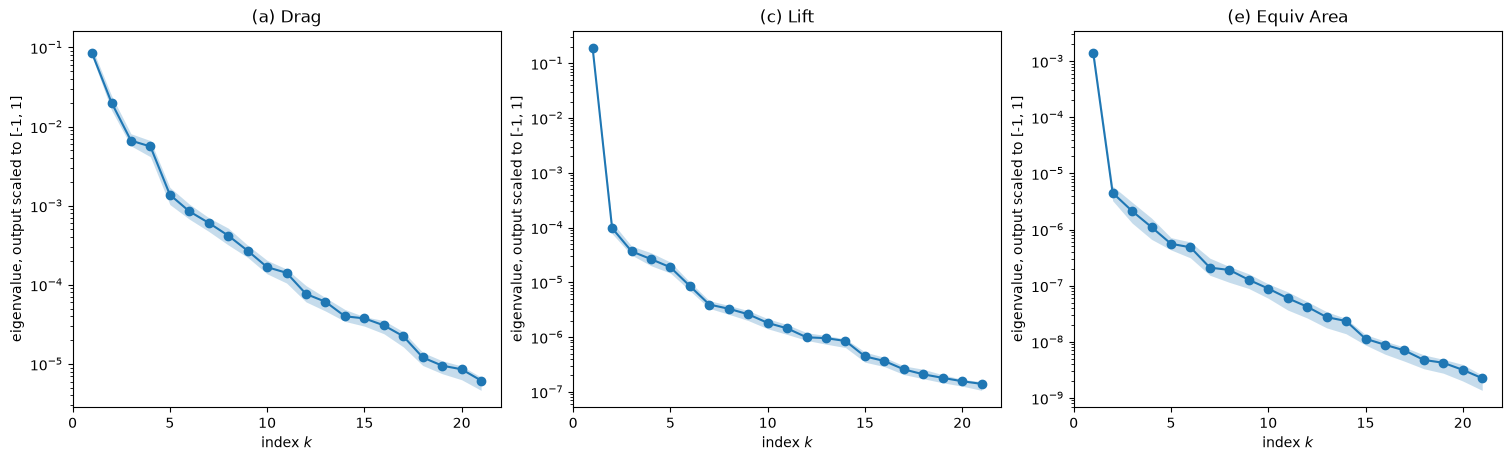

In [9]:
fig414 = {  # read off [1] Fig. 4.14 (p. 108), lambda_1..5
    'Lift': [0.19, 1.1e-4, 3.8e-5, 2.7e-5, 1.9e-5],
    'Drag': [0.086, 0.020, 0.0069, 0.0057, 0.0014],
    'Equiv Area': [1.3e-3, 5.2e-6, 2.2e-6, 1.1e-6, 5.7e-7]}
for q in qois:
    c2 = (2 / (f[q].max() - f[q].min()))**2
    lam = sub[q].eigenvalues[:5] * c2
    lam_std = sub[q].eigenvalues[0] / f[q].std()**2
    print(f'{q:>10}: lambda x (2/(max f - min f))^2 = {fmt(lam)}')
    print(f'{"Fig. 4.14":>10}:                                {fmt(fig414[q])}')
    print(f'{"":>10}  ratio to Fig. 4.14: {fmt(lam / np.array(fig414[q]))}; scaling by the standard deviation '
          f'instead: lambda_1 = {lam_std:.3g}, {lam_std / fig414[q][0]:.1f} x Fig. 4.14\n')

k = 21
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout='constrained')
for j, q in enumerate(['Drag', 'Lift', 'Equiv Area']):
    c2 = (2 / (f[q].max() - f[q].min()))**2
    boot = sub[q].bootstrap_eigenvalues[:, :k] * c2
    idx = np.arange(1, k + 1)
    axes[j].fill_between(idx, boot.min(axis=0), boot.max(axis=0), color='C0', alpha=0.25, linewidth=0)
    axes[j].semilogy(idx, sub[q].eigenvalues[:k] * c2, 'o-', color='C0')
    axes[j].set_xlabel('index $k$')
    axes[j].set_ylabel('eigenvalue, output scaled to [-1, 1]')
    axes[j].set_xticks(range(0, k + 1, 5))
    axes[j].set_title(f'({"ace"[j]}) {q}')

The scaled eigenvalues match Fig. 4.14 (a), (c) and (e): all fifteen printed values agree within 14%, most within 4%. The plots show the same features, including the drag spectrum's plateau at $\lambda_3 \approx \lambda_4$ and lift's secondary gap after $\lambda_5$, which [[1]][R1] p. 107 notes.

[[1]][R1] Fig. 4.15 (p. 109) shows the 1-dimensional sufficient summary plots. Its horizontal axes run from about −0.48 to 0.57. That range is reproduced when the active variable is computed from the physical inputs, $\mathbf w_1^T\mathbf x$ with $\mathbf x\in[-0.3, 0.3]^{105}$, which is 0.3 times the normalized active variable used above. [[1]][R1] §4.2 (pp. 78–79) normalizes the inputs, so this axis seems to be an inconsistency in the figure; it changes only the axis scale. We redraw Fig. 4.15 that way.

      Drag: w1^T x ranges over [-0.471, 0.459]; Drag ranges over [0.01717, 0.01982]
      Lift: w1^T x ranges over [-0.479, 0.571]; Lift ranges over [0.1228, 0.1525]
Equiv Area: w1^T x ranges over [-0.478, 0.567]; Equiv Area ranges over [5.546, 1666]


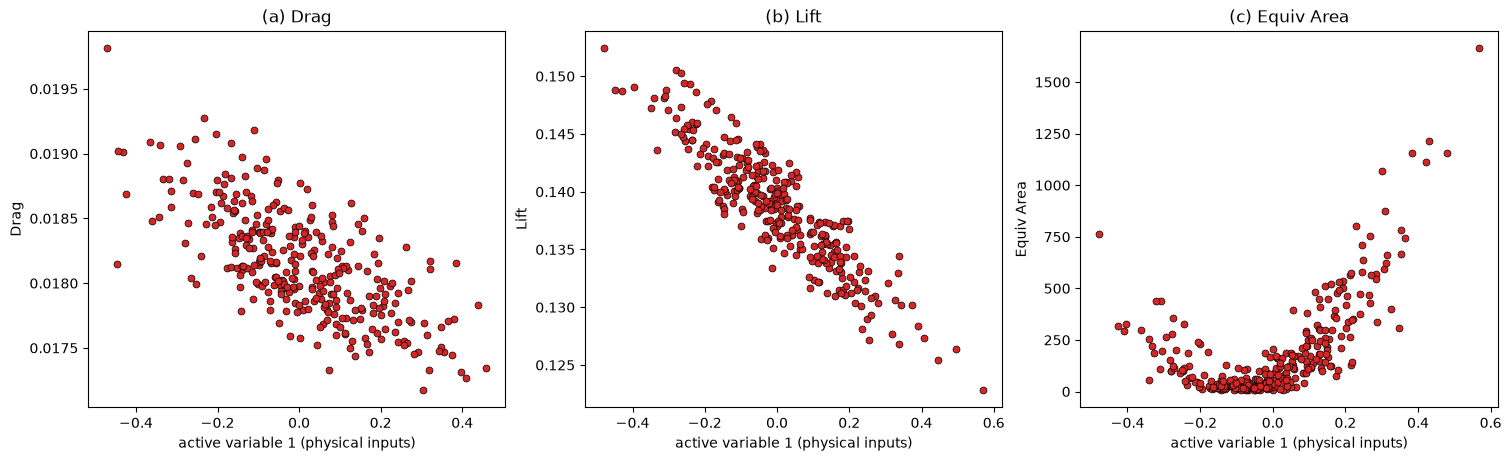

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout='constrained')
for j, q in enumerate(['Drag', 'Lift', 'Equiv Area']):
    y_phys = X @ sub[q].W[:, 0]          # active variable from the PHYSICAL inputs, as in [1] Fig. 4.15
    axes[j].scatter(y_phys, f[q], s=25, c='C3', edgecolors='k', linewidths=0.5)
    axes[j].set_xlabel('active variable 1 (physical inputs)')
    axes[j].set_ylabel(q)
    axes[j].set_title(f'({"abc"[j]}) {q}')
    print(f'{q:>10}: w1^T x ranges over [{y_phys.min():.3f}, {y_phys.max():.3f}]; '
          f'{q} ranges over [{f[q].min():.4g}, {f[q].max():.4g}]')

The ranges and the shapes match Fig. 4.15: lift and drag decrease along the active variable, and the equivalent area is a parabola whose largest values lie at the positive end.

The active subspaces we've constructed can be used for several applications, such as (constrained) optimization, integration, and surrogate modeling. [[2]][R2] discusses these applications for the ONERA M6 wing.

In [11]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 27.7 s
